# ms-11: Improve a design, then try to disprove the improvement

In [1]:
from pathlib import Path
import sys, json, hashlib, platform
from dataclasses import asdict, replace
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
ROOT = Path.cwd()
if not (ROOT/'simulations').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT/'simulations'))
from design_studies import (Design, order_metrics, spectral_sweep, bandwidth,
                           local_prediction, optimize_widths, grcwa_check)
from unit_cell_te import Cell, solve_cell, sample_ey
plt.rcParams.update({'figure.dpi': 125, 'font.size': 10, 'axes.spines.top': False,
                     'axes.spines.right': False})
OUT = ROOT/'data/design-studies'; OUT.mkdir(parents=True, exist_ok=True)
def metadata(design):
    import scipy
    return dict(parameters=asdict(design), units='um, degrees; incident-normalized power',
      conventions='exp(-i omega t), TE Ey, r at z=0, t at z=height',
      sources={name:hashlib.sha256((ROOT/'simulations'/name).read_text(encoding='utf-8').encode()).hexdigest()
               for name in ['design_studies.py','unit_cell_te.py','metasurface_synthesis.py']},
      environment={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__})
def geometry(ax, design, title):
    L=len(design.widths_um)*design.pitch_um; h=design.height_um
    ax.add_patch(Rectangle((0,h),L,.32,fc='#c3ddeb'))
    for j,w in enumerate(design.widths_um):
        ax.add_patch(Rectangle(((j+.5)*design.pitch_um-w/2,0),w,h,fc='#167b9b',ec='white'))
        ax.text((j+.5)*design.pitch_um,-.07,str(j+1),ha='center',fontsize=9)
    ax.axvline(0,c='#9866aa',ls='--');ax.axvline(L,c='#9866aa',ls='--')
    ax.set(xlim=(-.1,L+.1),ylim=(h+.32,-.4),xlabel='x (um)',ylabel='z (um)',title=title)
    ax.text(.05,.04,'TE: E along y; k along +z',transform=ax.transAxes,fontsize=8)
    ax.text(.05,.13,'Repeated in x; invariant in y',transform=ax.transAxes,fontsize=8)


Optimize the **six physical ridge widths**, not a synthetic response coordinate. Pitch, height and materials remain fixed. Start from Chapter 5's design and retain its full-wave result as a baseline. Bounded Powell searches use only T₊₁ at λ=1.55 µm and M=32. Freeze the best queried geometry before using finer harmonics, other wavelengths or perturbations. This small direct-solver baseline can later test an AI proposal from Chapter 10. See the [lab](../labs/11-inverse-design-lab.md).

In [2]:
baseline=Design()
result=optimize_widths(baseline,starts=2,maxfev=1000,half_order=32,bounds=(.08,.57),seed=17)
selected=replace(baseline,widths_um=tuple(result['best']['widths_um']))
# Save even a budget-exhausted or non-improving search before validation.
report=dict(metadata=metadata(baseline),optimization=result,selected_parameters=asdict(selected),
    stage='search_saved',refinement=[],held_out=[],perturbations=[],
    independent_implementation=dict(status='not run yet',checks=[]))
def save_report():
    (OUT/'inverse-design.json').write_text(json.dumps(report,indent=2,allow_nan=False)+'\n',encoding='utf-8')
save_report()
# Geometry is frozen here; subsequent checks are never fed back into this search.
checks=[]
for M in [32,64,96,144,192]:
    checks.append(dict(half_order=M,baseline=order_metrics(baseline.solve(M)),selected=order_metrics(selected.solve(M))))
validation=dict(improved=bool(checks[-1]['selected']['T']>checks[-1]['baseline']['T']),
    refinement_passed=bool(abs(checks[-1]['selected']['T']-checks[-2]['selected']['T'])<1e-4))
report.update(stage='refinement_checked',refinement=checks,validation=validation)
save_report()
print('Experiment checks (not publication approval):',validation)
print('Optimizer runs:',json.dumps(result['runs'],indent=2))
print('Baseline / selected, checked M=192:',checks[-1]['baseline']['T'],checks[-1]['selected']['T'])
print('Selected widths (um):',selected.widths_um)


Experiment checks (not publication approval): {'improved': True, 'refinement_passed': True}
Optimizer runs: [
  {
    "run": 0,
    "success": true,
    "message": "Optimization terminated successfully.",
    "evaluations": 74,
    "final_T": 0.738890784631474
  },
  {
    "run": 1,
    "success": true,
    "message": "Optimization terminated successfully.",
    "evaluations": 694,
    "final_T": 0.8893937978766874
  }
]
Baseline / selected, checked M=192: 0.8553551432162186 0.8893819518243993
Selected widths (um): (0.13723640529583608, 0.16518197975125032, 0.21951022970727538, 0.26300956024738753, 0.40168191418921106, 0.5077454465285082)


A success flag describes the stopping rule, not a global optimum or even improvement over the initial point. Keep the best feasible candidate seen across both starts, including the starting geometry. Report the evaluation budget and failed/worse searches; never select a candidate using the held-out results below and still call those results independent validation.

The search history is saved before refinement or held-out checks, then updated as checks complete. Improvement and refinement are recorded as flags so unsuccessful experiments remain reportable. The separate published-reference audit retains its strict acceptance requirements.


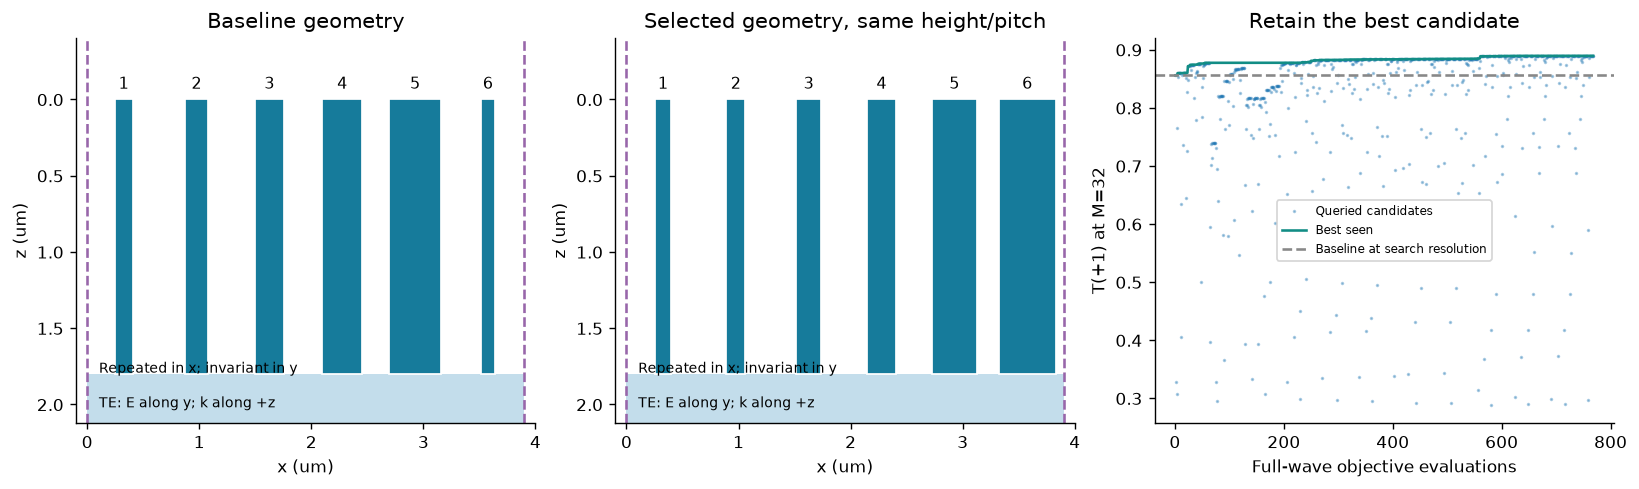

In [3]:
fig,ax=plt.subplots(1,3,figsize=(13,3.8),layout='constrained')
geometry(ax[0],baseline,'Baseline geometry');geometry(ax[1],selected,'Selected geometry, same height/pitch')
history=result['history'];ax[2].plot([r['evaluation'] for r in history],[r['T'] for r in history],'.',ms=2,alpha=.35,label='Queried candidates')
ax[2].plot([r['evaluation'] for r in history],[r['best_T'] for r in history],label='Best seen',c='#128d85')
ax[2].axhline(checks[0]['baseline']['T'],ls='--',c='#888',label='Baseline at search resolution')
ax[2].set(xlabel='Full-wave objective evaluations',ylabel='T(+1) at M=32',title='Retain the best candidate');ax[2].legend(fontsize=7)
plt.show()


In [4]:
# Withheld operating points: diagnostics, not a broadband training objective.
held_out=[]
for wl in [1.45,1.50,1.60,1.65]:
    held_out.append(dict(wavelength_um=wl,baseline=order_metrics(replace(baseline,wavelength_um=wl).solve(144)),
                        selected=order_metrics(replace(selected,wavelength_um=wl).solve(144))))
# Deterministic fabrication scenarios, not a probability distribution or yield.
perturbations=[]
for j in [-1,0,1,2,3,4,5]:
    for delta in [-.005,.005]:
        w=np.array(selected.widths_um)
        if j<0: w+=delta
        else: w[j]+=delta
        perturbations.append(dict(ridge='all' if j<0 else j+1,delta_um=delta,
            T=order_metrics(replace(selected,widths_um=tuple(w)).solve(144))['T']))
# Optional separate implementation; no commercial solver is needed.
external=[]
try:
    import grcwa
except ImportError:
    external_status='not run: install requirements-validation.txt and rerun this notebook'
else:
    ours=selected.solve(48)
    for pixels in [4096,8192]:
        other=grcwa_check(selected,48,pixels);idx=other['orders']+48
        error=max(abs(ours['R'][idx]-other['R']).max(),abs(ours['T'][idx]-other['T']).max())
        external.append(dict(half_order=48,pixels=pixels,max_order_power_error=float(error)))
    external_status=('passed' if external[-1]['max_order_power_error']<1e-4 else 'failed')+': separate RCWA implementation; not FEM/FDTD'
report.update(stage='independent_checks_complete',held_out=held_out,perturbations=perturbations,independent_implementation=dict(status=external_status,checks=external))
save_report()
print('Independent implementation:',external_status,external)
print('Held-out wavelength checks:',held_out)
print('Worst of 14 specified perturbations:',min(r['T'] for r in perturbations))


Independent implementation: passed: separate RCWA implementation; not FEM/FDTD [{'half_order': 48, 'pixels': 4096, 'max_order_power_error': 7.567330212680107e-07}, {'half_order': 48, 'pixels': 8192, 'max_order_power_error': 2.841090168109045e-07}]
Held-out wavelength checks: [{'wavelength_um': 1.45, 'baseline': {'T': 0.7731460421202802, 'R': 0.001750870910749018, 't_real': 0.7207287304522131, 't_imag': -0.11217333969454259, 'total_T': 0.8888711599327888, 'total_R': 0.11112884006721216, 'balance_error': 8.881784197001252e-16, 'residual': 4.621940372351977e-16}, 'selected': {'T': 0.7753046845668303, 'R': 0.0012380414989124192, 't_real': 0.4158045932282419, 't_imag': -0.6005203990063281, 'total_T': 0.8556527856768928, 'total_R': 0.14434721432310724, 'balance_error': 1.1102230246251565e-16, 'residual': 6.869692573402599e-16}}, {'wavelength_um': 1.5, 'baseline': {'T': 0.8697918339188785, 'R': 5.229182178262241e-05, 't_real': 0.5578284516801364, 't_imag': -0.5373500371261473, 'total_T': 0.91

The grcwa comparison, when installed, matches all retained orders at the same M=48 and refines its material raster independently. The published run includes it. Harmonic refinement and grcwa are different checks, but both remain in the RCWA family. Four wavelengths and fourteen ±5 nm width scenarios are diagnostics, not a proof of broadband performance or fabrication yield. No FEM/FDTD or experiment has been run.

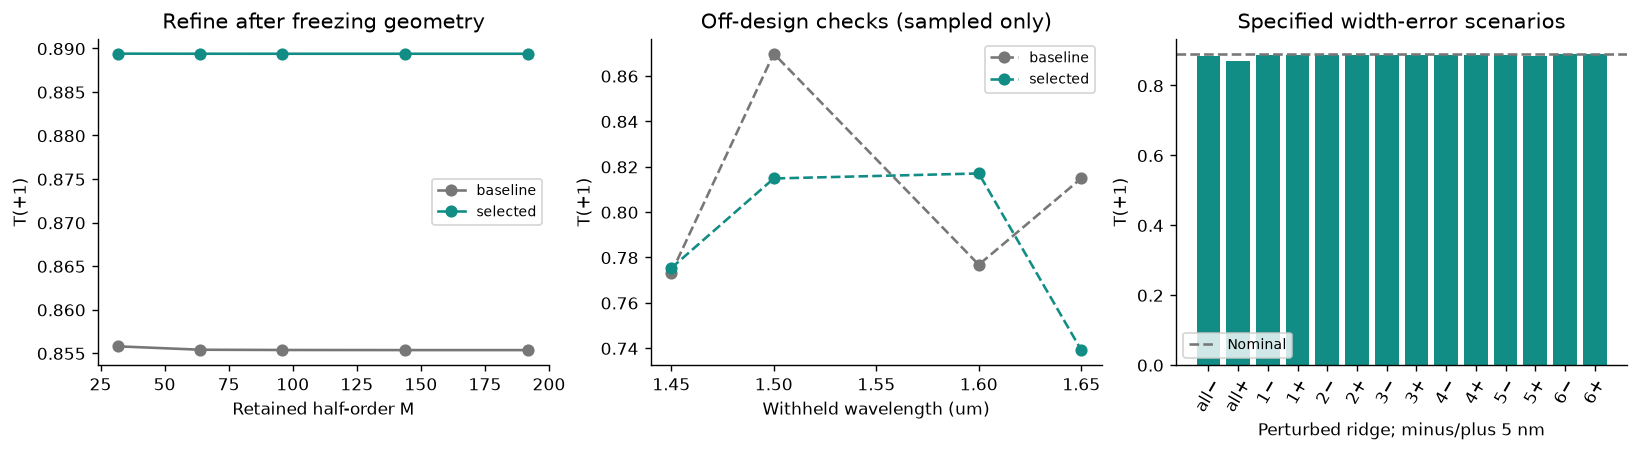

In [5]:
fig,ax=plt.subplots(1,3,figsize=(13,3.5),layout='constrained')
for name,color in [('baseline','#777'),('selected','#128d85')]:
    ax[0].plot([c['half_order'] for c in checks],[c[name]['T'] for c in checks],'o-',label=name,c=color)
    ax[1].plot([c['wavelength_um'] for c in held_out],[c[name]['T'] for c in held_out],'o--',label=name,c=color)
ax[0].set(xlabel='Retained half-order M',ylabel='T(+1)',title='Refine after freezing geometry');ax[0].legend(fontsize=8)
ax[1].set(xlabel='Withheld wavelength (um)',ylabel='T(+1)',title='Off-design checks (sampled only)');ax[1].legend(fontsize=8)
ax[2].bar(np.arange(14),[r['T'] for r in perturbations],color='#128d85')
ax[2].axhline(checks[-1]['selected']['T'],c='#777',ls='--',label='Nominal')
ax[2].set(xticks=np.arange(14),xticklabels=[str(r['ridge'])+('−' if r['delta_um']<0 else '+') for r in perturbations],
    xlabel='Perturbed ridge; minus/plus 5 nm',ylabel='T(+1)',title='Specified width-error scenarios');ax[2].tick_params(axis='x',rotation=60);ax[2].legend(fontsize=8)
plt.show()
report['stage']='investigation_complete'
save_report()


**Submit:** the original baseline, frozen widths, bounded search history including stopping reasons, held-out checks and limitations. Extension: compare an AI-proposed geometry under the same total full-wave evaluation budget, including training-label generation. If you change the objective to a band or to robust performance, reserve a new independent validation set.